# Risk-Aware Portfolio Optimization
### Choosing which projects to fund, and when, under uncertainty: Monte Carlo simulation + integer optimization + an AI-agent interface (MCP)

**Case:** *Nordhavn Motors*, a fictional global automaker, has **32 project requests worth \$190M** but only a **\$100M budget** for the next two years. Its teams are limited, some projects depend on others, and two projects are required by law. On top of that, project cost estimates are usually too optimistic.

**The leadership question:** *Which projects should we fund, when should each start, and how confident can we be that we'll stay within budget?*

**What this notebook does, step by step**
| Step | What happens | Technique |
|---|---|---|
| 1 | Create and explore the portfolio data | pandas |
| 2 | Model how wrong estimates usually are | Monte Carlo simulation (calibrated to published research) |
| 3 | Build the "common method" plan: rank by strategic score | greedy heuristic |
| 4 | Build the optimized plan | integer programming (Google OR-Tools CP-SAT) |
| 5 | Make both plans safe: at most 20% chance of going over budget | chance-constrained planning (bisection search) |
| 6 | Compare all plans, with charts | simulation of 5,000 futures per plan |
| 7 | What-if scenarios and the team bottleneck | scenario analysis |
| 8 | How much value each budget level buys | efficient frontier |
| 9 | The final roadmap | Gantt chart |
| 10 | Let an AI assistant run all of this | MCP (Model Context Protocol) server |

**Headline results** (budget \$100M, 5,000 simulated futures per plan)
- The common method (rank by score) has a **92% chance of going over budget**.
- At the same budget, the optimizer creates about **2.3×** the typical value.
- At the *same* safety level (≤20% risk), the optimizer creates about **3.4×** the value of ranking by score, and keeps about **\$15M** as a contingency reserve.
- The **data/AI team is the bottleneck**: losing a quarter of it costs about \$11M of value.

## 0. Setup
Run this once. It installs the free libraries we use:
- **pandas / numpy**: tables and math
- **matplotlib**: charts
- **ortools**: Google's free optimization solver
- **mcp**: the Model Context Protocol SDK, used in step 10

**All the code is in this notebook.** Run the cells from top to bottom (Shift + Enter, or Run → Run All Cells).

In [1]:
%pip install -q ortools pandas numpy matplotlib "mcp[cli]<2"

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import os, json, sys, inspect
from ortools.sat.python import cp_model

pd.set_option("display.width", 170); pd.set_option("display.max_columns", 20)
BUDGET = 100.0      # the real budget: $100M
print("Ready ✅")

Ready ✅


---
## Step 1: The data

### 1.1 Create it
The cell below creates 32 realistic projects across six strategic themes (Electrification, Software-Defined Vehicle, Smart Factory, Customer & Digital, Core IT & Compliance, Supply Chain). The random seed is fixed, so everyone gets the same data.

**Why made-up data?** Real company portfolio data is confidential. What matters is that the **risk model** (step 2) is calibrated to real published research.

In [3]:
os.makedirs("data", exist_ok=True)

rng = np.random.default_rng(42)
SKILLS = ["software", "data_ai", "mechanical", "pmo"]
THEMES = {
    "Electrification":        ["EV battery mgmt software", "Charging network integration", "EV platform cost-down", "Battery supplier dual-sourcing", "800V architecture pilot"],
    "Software-Defined Vehicle": ["OTA update platform", "ADAS perception model v3", "In-car voice assistant", "Vehicle OS consolidation", "Digital twin of drivetrain", "Cybersecurity (UNECE R155)"],
    "Smart Factory":          ["Predictive maintenance – Plant A", "Predictive maintenance – Plant B", "Vision-based quality inspection", "Factory IoT data lake", "Robotic paint line upgrade", "Energy optimization – plants"],
    "Customer & Digital":     ["Online direct-sales store", "Dealer CRM migration", "Connected-car app 2.0", "Subscription services billing", "Customer 360 data product"],
    "Core IT & Compliance":   ["SAP S/4HANA migration – Finance", "SAP S/4HANA migration – Supply", "EU battery passport (regulatory)", "Data governance & catalog", "Cloud cost optimization", "Identity & access modernization"],
    "Supply Chain":           ["Demand forecasting ML", "Supplier risk early-warning", "Inventory optimization – spare parts", "Logistics route optimization"],
}
MANDATORY = {"Cybersecurity (UNECE R155)", "EU battery passport (regulatory)"}

rows, i = [], 0
for theme, names in THEMES.items():
    for name in names:
        i += 1
        complexity = rng.choice(["low", "medium", "high"], p=[0.3, 0.45, 0.25])
        dur = {"low": rng.integers(1, 3), "medium": rng.integers(2, 4), "high": rng.integers(3, 5)}[complexity]  # quarters
        cost = round(float({"low": rng.uniform(1, 3), "medium": rng.uniform(3, 7), "high": rng.uniform(7, 15)}[complexity]), 1)  # $M
        # quarterly benefit ($M/quarter) once delivered; ROI varies a lot (that's realistic)
        benefit_q = round(float(cost * rng.uniform(0.08, 0.35)), 2)
        strategic = int(rng.integers(3, 11))  # 1-10 alignment score (what execs usually rank by)
        fte = {s: 0 for s in SKILLS}
        main = {"Electrification": "mechanical", "Software-Defined Vehicle": "software", "Smart Factory": "data_ai",
                "Customer & Digital": "software", "Core IT & Compliance": "software", "Supply Chain": "data_ai"}[theme]
        base = cost / dur * 4.0  # FTE per quarter roughly proportional to spend rate
        fte[main] = round(base * 0.6, 1)
        for s in SKILLS:
            if s != main:
                fte[s] = round(base * rng.uniform(0.05, 0.25), 1)
        if "ML" in name or "model" in name or "Predictive" in name or "optimization" in name.lower() or "data" in name.lower():
            fte["data_ai"] = round(fte["data_ai"] + base * 0.3, 1)
        rows.append(dict(id=f"P{i:02d}", name=name, theme=theme, complexity=complexity, duration_q=int(dur),
                         cost_musd=cost, benefit_musd_per_q=benefit_q, strategic_score=strategic,
                         mandatory=name in MANDATORY, **{f"fte_{s}": fte[s] for s in SKILLS}))

df = pd.DataFrame(rows)
# Dependencies (predecessor must finish before successor starts)
deps = [("Factory IoT data lake", "Predictive maintenance – Plant A"), ("Factory IoT data lake", "Predictive maintenance – Plant B"),
        ("Factory IoT data lake", "Energy optimization – plants"), ("OTA update platform", "ADAS perception model v3"),
        ("Vehicle OS consolidation", "In-car voice assistant"), ("Customer 360 data product", "Connected-car app 2.0"),
        ("SAP S/4HANA migration – Finance", "SAP S/4HANA migration – Supply"), ("Data governance & catalog", "Customer 360 data product"),
        ("SAP S/4HANA migration – Supply", "Inventory optimization – spare parts"), ("Battery supplier dual-sourcing", "EU battery passport (regulatory)")]
name2id = dict(zip(df.name, df.id))
pd.DataFrame([(name2id[a], name2id[b]) for a, b in deps], columns=["predecessor", "successor"]).to_csv("data/dependencies.csv", index=False)
df.to_csv("data/initiatives.csv", index=False)

# Quarterly capacity (FTE) per skill pool over an 8-quarter plan horizon
cap = pd.DataFrame({"quarter": range(8), "software": 42, "data_ai": 20, "mechanical": 22, "pmo": 10})
cap.to_csv("data/capacity.csv", index=False)
print(f"\n{len(df)} initiatives, total ask ${df.cost_musd.sum():.0f}M")


32 initiatives, total ask $190M


**What the cell above did**
- `rng = np.random.default_rng(42)` makes the random numbers **repeatable**: everyone gets the same data.
- For each project it picks a complexity, a duration (1–4 quarters), a cost, a quarterly benefit, a strategic score, and the people needed from each team (bigger, faster projects need more people).
- It lists the **dependencies** (which project must finish first) and the **team sizes** per quarter.
- It saves three files in the `data/` folder: `initiatives.csv`, `dependencies.csv`, `capacity.csv`.

Now we load them back as tables with a tiny helper, `load()`:

In [4]:
def load(path="data"):
    """Read the three CSV files created above."""
    df = pd.read_csv(f"{path}/initiatives.csv").set_index("id")     # one row per project
    deps = pd.read_csv(f"{path}/dependencies.csv")                  # predecessor must finish before successor starts
    cap = pd.read_csv(f"{path}/capacity.csv").set_index("quarter")  # people available per team per quarter
    return df, deps, cap

df, deps, cap = load()
print(f"{len(df)} projects | {len(deps)} dependencies | {len(cap)} quarters of team capacity")

32 projects | 10 dependencies | 8 quarters of team capacity


### 1.2 What each column means
| Column | Meaning | Example (P30) |
|---|---|---|
| `id`, `name`, `theme` | the project and the strategic theme it belongs to | P30, Supplier risk early-warning, Supply Chain |
| `complexity` | low / medium / high. Complex projects are riskier | medium |
| `duration_q` | planned duration in **quarters** (1 quarter = 3 months) | 3 |
| `cost_musd` | the team's cost **estimate** in \$ millions | 14.2 |
| `benefit_musd_per_q` | money earned or saved **every quarter after it's finished** | 4.89 |
| `strategic_score` | how important leadership *feels* it is (3–10) | 10 |
| `mandatory` | required by law (cybersecurity rule UNECE R155, EU battery passport) | False |
| `fte_software`, `fte_data_ai`, `fte_mechanical`, `fte_pmo` | people needed from each team **per quarter** while it runs (FTE = full-time employee) | … |

In [5]:
df.head(10)

,name,theme,complexity,duration_q,cost_musd,benefit_musd_per_q,strategic_score,mandatory,fte_software,fte_data_ai,fte_mechanical,fte_pmo
id,,,,,,,,,,,,
P01,EV battery mgmt software,Electrification,high,3,14.8,4.23,9,False,4.1,1.5,11.8,2.8
P02,Charging network integration,Electrification,medium,3,4.8,1.10,8,False,0.4,1.4,3.8,1.1
P03,EV platform cost-down,Electrification,high,3,8.6,1.77,10,False,0.7,0.9,6.9,2.1
P04,Battery supplier dual-sourcing,Electrification,medium,3,4.9,0.56,5,False,0.9,0.6,3.9,1.2
P05,800V architecture pilot,Electrification,medium,3,6.3,1.16,8,False,0.9,1.6,5.0,0.7
P06,OTA update platform,Software-Defined Vehicle,low,2,2.3,0.47,9,False,2.8,0.8,0.4,0.3
P07,ADAS perception model v3,Software-Defined Vehicle,medium,2,5.5,1.27,7,False,6.6,4.5,0.6,1.5
P08,In-car voice assistant,Software-Defined Vehicle,low,1,1.5,0.24,9,False,3.6,1.1,1.0,1.2
P09,Vehicle OS consolidation,Software-Defined Vehicle,medium,2,3.1,0.85,9,False,3.7,0.9,0.5,0.9


### 1.3 The big picture: more requests than money

In [6]:
by_theme = df.groupby("theme").agg(projects=("name", "count"), requested_musd=("cost_musd", "sum")).round(1)
display(by_theme)
print(f"Total requested: ${df.cost_musd.sum():.0f}M   |   Budget: ${BUDGET:.0f}M   →  we can fund only about half.")

,projects,requested_musd
theme,,
Core IT & Compliance,6,27.6
Customer & Digital,5,38.3
Electrification,5,39.4
Smart Factory,6,27.0
Software-Defined Vehicle,6,26.9
Supply Chain,4,30.9


Total requested: $190M   |   Budget: $100M   →  we can fund only about half.


### 1.4 Dependencies and team sizes
- **Dependencies:** the *predecessor* must finish before the *successor* can start. For example, you can't run predictive maintenance before the factory data lake exists.
- **Capacity:** how many people each team has in every quarter. A plan can never need more people than this.

In [7]:
display(deps.assign(predecessor_name=deps.predecessor.map(df.name), successor_name=deps.successor.map(df.name)))
print("People available per quarter:", cap.iloc[0].to_dict())

,predecessor,successor,predecessor_name,successor_name
0,P15,P12,Factory IoT data lake,Predictive maintenance – Plant A
1,P15,P13,Factory IoT data lake,Predictive maintenance – Plant B
2,P15,P17,Factory IoT data lake,Energy optimization – plants
3,P06,P07,OTA update platform,ADAS perception model v3
4,P09,P08,Vehicle OS consolidation,In-car voice assistant
5,P22,P20,Customer 360 data product,Connected-car app 2.0
6,P23,P24,SAP S/4HANA migration – Finance,SAP S/4HANA migration – Supply
7,P26,P22,Data governance & catalog,Customer 360 data product
8,P24,P31,SAP S/4HANA migration – Supply,Inventory optimization – spare parts
9,P04,P25,Battery supplier dual-sourcing,EU battery passport (regulatory)


People available per quarter: {'software': 42, 'data_ai': 20, 'mechanical': 22, 'pmo': 10}


### 1.5 Does the strategic score tell us which projects pay off?
**Payback time** = cost ÷ benefit per quarter = how many quarters of benefit it takes to earn the cost back. Lower is better.

**How to read this chart:** each dot is a project. Further right = leadership thinks it's more important. Lower = it pays back faster. If the score told us about value, the dots would slope downward from left to right.

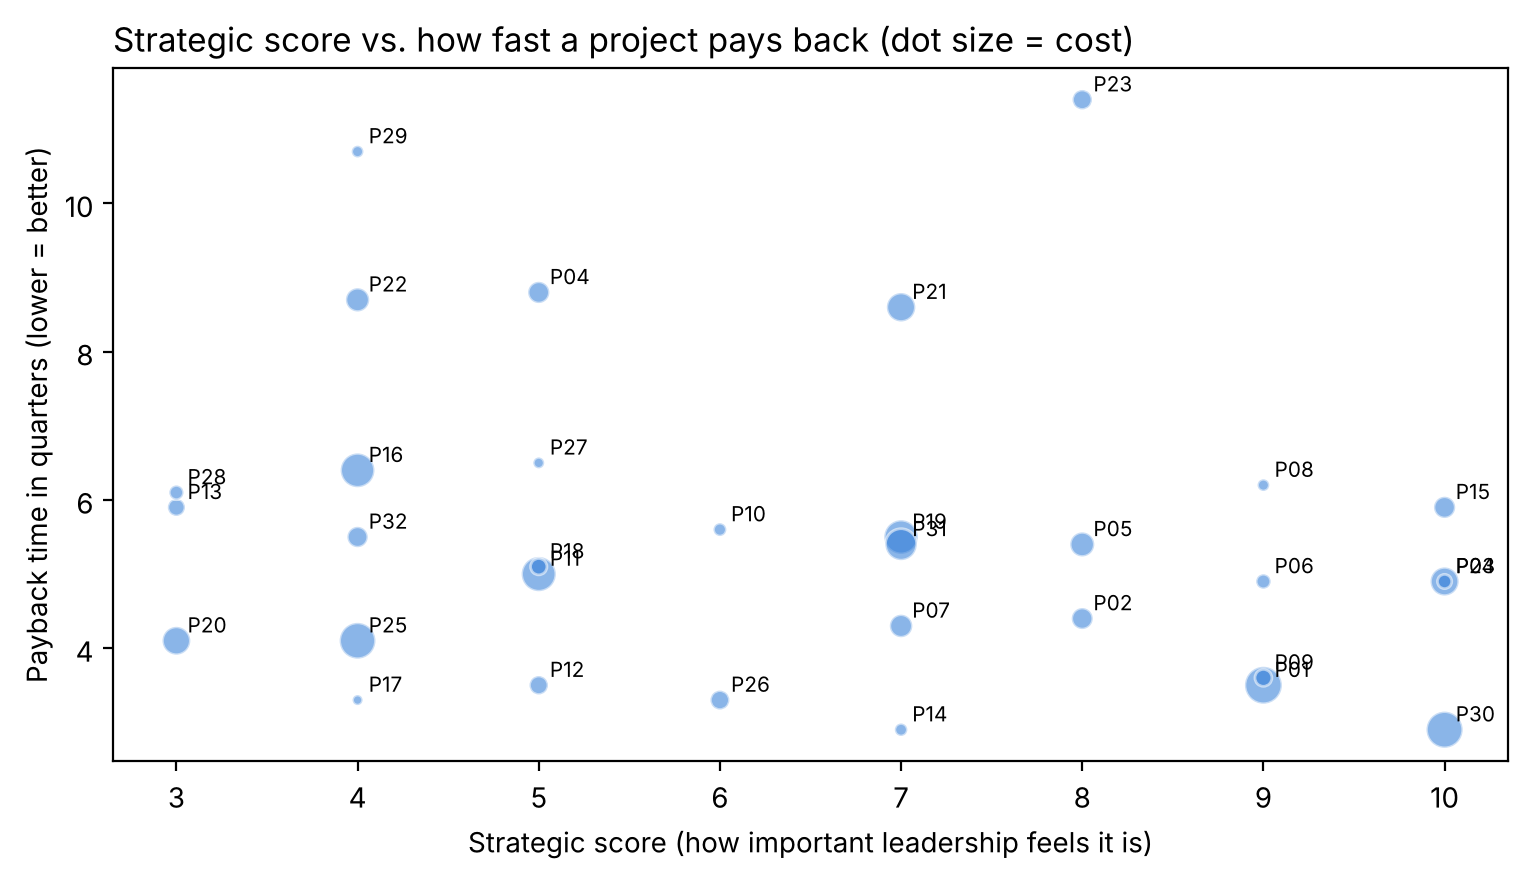

Correlation between score and payback time: -0.19


In [8]:
df["payback_quarters"] = (df.cost_musd / df.benefit_musd_per_q).round(1)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(df.strategic_score, df.payback_quarters, s=df.cost_musd * 12, color="#2a78d6", alpha=0.55, edgecolor="white")
for i, r in df.iterrows():
    ax.annotate(i, (r.strategic_score, r.payback_quarters), fontsize=7.5, xytext=(4, 3), textcoords="offset points")
ax.set_xlabel("Strategic score (how important leadership feels it is)")
ax.set_ylabel("Payback time in quarters (lower = better)")
ax.set_title("Strategic score vs. how fast a project pays back (dot size = cost)", loc="left")
plt.show()
print("Correlation between score and payback time:", round(df.strategic_score.corr(df.payback_quarters), 2))

**What it shows:** the dots form a cloud with no clear slope (correlation is close to 0). **The strategic score says almost nothing about how fast a project pays back.** So a plan that only ranks by score will miss value. That's the first hint of why optimization helps.

---
## Step 2: How wrong are estimates? (Monte Carlo simulation)

### 2.1 The idea
A cost estimate is one guess. Reality is a range. Research by **Flyvbjerg & Budzier** (*Harvard Business Review*, 2011) on **1,471 IT projects** found:
- the **average cost overrun was 27%** (a \$10M estimate typically became \$12.7M)
- about **1 in 6 projects was a "black swan"**, with a cost overrun of about 200% (roughly 3× the plan)

**Monte Carlo simulation** means imagining many possible futures with random but realistic outcomes, then counting what happens. In the code below, `sample_multipliers()` draws, for **every project in every one of 5,000 futures**:
- a **cost multiplier**: actual cost = estimate × multiplier
- a **duration multiplier**: actual duration = plan × multiplier

It uses three ingredients:
1. **Normal uncertainty**, bigger for complex projects
2. **Black swans**: a small chance of a huge overrun (8% / 15% / 25% for low / medium / high complexity, about 1 in 6 overall)
3. **A shared shock**: one random number per future that pushes *all* projects up or down together (inflation, talent shortage), because in real life overruns are **correlated**

### 2.2 The code
First the settings: team names, the 2-year plan window, and the uncertainty levels by complexity.

In [9]:
SKILLS = ["software", "data_ai", "mechanical", "pmo"]   # the four teams
PLAN_Q = 8          # every project must start AND finish inside quarters 0..7 (2 years)
BENEFIT_H = 12      # we count benefits until quarter 12 (a 3-year view)

# How wrong estimates usually are. Calibrated to Flyvbjerg & Budzier (Harvard Business Review, 2011):
# 1,471 IT projects, average cost overrun of about 27%, and about 1 in 6 projects a "black swan" (huge overrun).
SIGMA  = {"low": 0.10, "medium": 0.18, "high": 0.28}    # normal uncertainty, bigger for complex projects
TAIL_P = {"low": 0.08, "medium": 0.15, "high": 0.25}    # chance of a black swan (about 1 in 6 on average)

`sample_multipliers()` creates the random futures. It returns two big tables (5,000 rows = futures, one column per project), like an Excel sheet with 5,000 rows:

In [10]:
def sample_multipliers(df, n_sims=5000, seed=0, corr=0.10):
    """
    For every imagined future (row) and every project (column), draw:
        cost multiplier      actual cost     = estimate x multiplier
        duration multiplier  actual duration = plan     x multiplier
    Three ingredients:
        1. normal uncertainty (lognormal: always positive, longer tail to the right)
        2. black swans: with a small chance, cost x 1.8-3.0 and duration x 1.4-1.9
        3. a shared shock g: one number per future that pushes ALL projects up or down together
           (inflation, a talent shortage...). It makes overruns "correlated", as they are in real life.
    Returns two arrays shaped (n_sims, number of projects), like an Excel sheet of 5,000 rows.
    """
    rng = np.random.default_rng(seed)            # seed = repeatable "random" numbers
    n = len(df)
    sig = df.complexity.map(SIGMA).values
    tail = df.complexity.map(TAIL_P).values
    g = rng.normal(0, corr, size=(n_sims, 1))    # shared shock: same value for every project in a row
    cost_m = np.exp(0.01 + sig * rng.normal(0, 1, size=(n_sims, n)) + g)
    dur_m = np.exp(0.08 + sig * rng.normal(0, 1, size=(n_sims, n)) + g)
    swan = rng.random((n_sims, n)) < tail        # black-swan dice roll for every cell
    cost_m = np.where(swan, cost_m * rng.uniform(1.8, 3.0, (n_sims, n)), cost_m)
    dur_m = np.where(swan, dur_m * rng.uniform(1.4, 1.9, (n_sims, n)), dur_m)
    return cost_m, dur_m

`risk_profile()` summarizes those futures **per project**: typical (P50), cautious (P80) and average cost, plus realistic durations.

In [11]:
def risk_profile(df, n_sims=5000, seed=0):
    """Per-project summary of the simulated futures: typical (P50), cautious (P80) and average cost and duration."""
    cm, dm = sample_multipliers(df, n_sims, seed)
    out = df[["name", "cost_musd", "duration_q"]].copy()
    out["cost_p50"] = np.percentile(cm, 50, axis=0) * df.cost_musd.values
    out["cost_p80"] = np.percentile(cm, 80, axis=0) * df.cost_musd.values
    out["dur_p80"] = np.ceil(np.percentile(dm, 80, axis=0) * df.duration_q.values - 1e-9).astype(int)
    out["cost_mean"] = cm.mean(axis=0) * df.cost_musd.values          # "realistic" average cost
    out["dur_mean"] = np.ceil(dm.mean(axis=0) * df.duration_q.values - 0.25).astype(int)  # rounded up if > 1/4 quarter over
    out["mean_cost_overrun_%"] = (cm.mean(axis=0) - 1) * 100
    return out

### 2.3 Check the calibration
Calibration means checking that the model's average overrun matches the research (about 27%).

In [12]:
rp = risk_profile(df)
print(f"Average simulated cost overrun: {rp['mean_cost_overrun_%'].mean():.0f}%   (research: ~27%) ✅")

Average simulated cost overrun: 27%   (research: ~27%) ✅


### 2.4 Estimates vs. realistic costs
For each project: the team's **estimate**, the **typical** simulated cost (P50, the middle of 5,000 futures), the **cautious** cost (P80, meaning 80% of futures cost less), and the **average** cost including black swans.

In [13]:
view = rp[["name", "cost_musd", "cost_p50", "cost_p80", "cost_mean", "duration_q", "dur_mean"]].round(1)
view.columns = ["project", "estimate $M", "typical (P50) $M", "cautious (P80) $M", "average $M", "planned quarters", "realistic quarters"]
display(view.head(10))
print(f"All 32 projects: estimates add to ${df.cost_musd.sum():.0f}M, realistic average costs add to ${rp.cost_mean.sum():.0f}M")

,project,estimate $M,typical (P50) $M,cautious (P80) $M,average $M,planned quarters,realistic quarters
id,,,,,,,
P01,EV battery mgmt software,14.8,16.8,28.2,21.0,3,4
P02,Charging network integration,4.8,5.1,6.7,6.0,3,4
P03,EV platform cost-down,8.6,9.9,16.8,12.4,3,4
P04,Battery supplier dual-sourcing,4.9,5.2,6.9,6.2,3,4
P05,800V architecture pilot,6.3,6.7,8.9,7.9,3,4
P06,OTA update platform,2.3,2.4,2.7,2.6,2,3
P07,ADAS perception model v3,5.5,5.8,7.6,6.8,2,3
P08,In-car voice assistant,1.5,1.5,1.8,1.7,1,1
P09,Vehicle OS consolidation,3.1,3.3,4.3,3.9,2,3


All 32 projects: estimates add to $190M, realistic average costs add to $256M


**How to read it:** look at P01. The team says \$14.8M, but averaged over all futures it costs about \$21M. Complex projects grow the most. **Any plan built on the estimates alone will be too optimistic.**

---
## Step 3: Plan A, the common method ("rank by strategic score")

Many organizations decide like this (the function `greedy_by_score()` below):
1. Fund the projects required by law, plus anything they depend on.
2. Go down the list by strategic score and fund each project if it still fits in the \$100M.
3. Start each project in the earliest quarter where every team has enough free people.

This is a **greedy heuristic**: a reasonable rule of thumb that looks at one project at a time.

In [14]:
def greedy_by_score(df, deps, cap, budget):
    """
    How many companies decide today:
      1. fund the legally required projects (and anything they depend on) first
      2. go down the list by strategic score; fund a project if it still fits in the budget
      3. start each one in the earliest quarter where every team has enough free people
    Fast and reasonable, but it looks at one project at a time, never at combinations.
    """
    load_ = {k: np.zeros(PLAN_Q) for k in SKILLS}        # people already booked, per team per quarter
    chosen, spent = {}, 0.0
    preds = deps.groupby("successor").predecessor.apply(list).to_dict()
    must = set(df.index[df.mandatory])                   # required projects + their prerequisites
    stack = list(must)
    while stack:
        for p in preds.get(stack.pop(), []):
            if p not in must:
                must.add(p); stack.append(p)
    order = df.assign(_must=df.index.isin(must)).sort_values(["_must", "strategic_score"], ascending=False).index
    for _ in range(2):                                   # 2nd pass picks up items whose prerequisites came later
        for i in order:
            if i in chosen or spent + df.loc[i, "cost_musd"] > budget:
                continue
            ps = preds.get(i, [])
            if any(p not in chosen for p in ps):
                continue
            d = int(df.loc[i, "duration_q"])
            earliest = max([chosen[p] + int(df.loc[p, "duration_q"]) for p in ps], default=0)
            for s in range(earliest, PLAN_Q - d + 1):
                if all(load_[k][s:s + d].max() + df.loc[i, f"fte_{k}"] <= cap[k].iloc[s:s + d].min() for k in SKILLS):
                    for k in SKILLS:
                        load_[k][s:s + d] += df.loc[i, f"fte_{k}"]
                    chosen[i], spent = s, spent + df.loc[i, "cost_musd"]
                    break
    plan = pd.DataFrame({"start_q": chosen}).rename_axis("id")
    plan["name"] = df.loc[plan.index, "name"]
    plan["planned_cost"] = df.loc[plan.index, "cost_musd"]
    return {"status": "HEURISTIC", "plan": plan.sort_values("start_q")}

In [15]:
planA = greedy_by_score(df, deps, cap, BUDGET)
display(planA["plan"])
print(f"Plan A funds {len(planA['plan'])} projects. Their estimates add to ${planA['plan'].planned_cost.sum():.1f}M.")

,start_q,name,planned_cost
id,,,
P04,0,Battery supplier dual-sourcing,4.9
P11,0,Cybersecurity (UNECE R155),12.7
P03,0,EV platform cost-down,8.6
P15,0,Factory IoT data lake,4.9
P06,0,OTA update platform,2.3
P09,0,Vehicle OS consolidation,3.1
P02,0,Charging network integration,4.8
P23,2,SAP S/4HANA migration – Finance,4.1
P27,2,Cloud cost optimization,1.3


Plan A funds 16 projects. Their estimates add to $99.7M.


`start_q` is the quarter the project starts. 0 = the first quarter of year 1, 7 = the last quarter of year 2.

### 3.1 Test Plan A in 5,000 futures
`simulate_plan()` runs the plan through 5,000 imagined futures. In each future it calculates the actual total cost, and the **net value** = 3-year benefits − actual costs. A project that finishes late earns for fewer quarters, and a project can't start until the projects it depends on have *actually* finished.

It returns a summary: the chance of going over budget, the typical cost, and bad / typical / good-case value.

In [16]:
def simulate_plan(df, deps, plan, budget, n_sims=5000, seed=1):
    """
    Test a plan (a list of projects + their start quarters) in 5,000 imagined futures.
    In each future:
      - every project gets a random actual cost and duration
      - a project cannot start before its predecessors ACTUALLY finish (delays ripple down)
      - benefit = benefit per quarter x the number of quarters between its finish and quarter 12
      - net value = total benefit - total actual cost
    Returns a summary:
      prob_over_budget   share of futures where total actual cost > budget
      cost_p50/p80       typical / cautious total cost
      net_value_p10/50/90  bad case / typical / good case value
    """
    ids = list(plan.index)
    sub = df.loc[ids]
    cm, dm = sample_multipliers(sub, n_sims, seed)
    cost = cm * sub.cost_musd.values
    dur = dm * sub.duration_q.values
    pos = {i: k for k, i in enumerate(ids)}
    preds = (deps[deps.successor.isin(ids) & deps.predecessor.isin(ids)]
             .groupby("successor").predecessor.apply(list).to_dict())
    finish = np.zeros_like(dur)
    for i in sorted(ids, key=lambda i: plan.loc[i, "start_q"]):
        k = pos[i]
        start = np.full(n_sims, float(plan.loc[i, "start_q"]))
        for p in preds.get(i, []):                       # wait for predecessors to really finish
            start = np.maximum(start, finish[:, pos[p]])
        finish[:, k] = start + dur[:, k]
    benefit = (np.clip(BENEFIT_H - finish, 0, None) * sub.benefit_musd_per_q.values).sum(axis=1)
    total_cost = cost.sum(axis=1)
    planned_finish = plan.start_q.values + sub.duration_q.values
    late = (finish - planned_finish) > 1.0               # more than one quarter late
    return {
        "n_projects": len(ids),
        "planned_cost": round(float(sub.cost_musd.sum()), 1),
        "cost_p50": round(float(np.percentile(total_cost, 50)), 1),
        "cost_p80": round(float(np.percentile(total_cost, 80)), 1),
        "prob_over_budget": round(float((total_cost > budget).mean()), 3),
        "net_value_p10": round(float(np.percentile(benefit - total_cost, 10)), 1),
        "net_value_p50": round(float(np.percentile(benefit - total_cost, 50)), 1),
        "net_value_p90": round(float(np.percentile(benefit - total_cost, 90)), 1),
        "prob_late_by_project": dict(zip(ids, np.round(late.mean(axis=0), 2).tolist())),
        "_total_cost": total_cost,            # all 5,000 simulated costs (for charts)
        "_net_value": benefit - total_cost,   # all 5,000 simulated values (for charts)
    }

In [17]:
simA = simulate_plan(df, deps, planA["plan"], BUDGET)
print(f"On paper Plan A costs ${simA['planned_cost']}M.")
print(f"In the typical future it really costs ${simA['cost_p50']}M.")
print(f"It goes over the $100M budget in {simA['prob_over_budget']:.0%} of the 5,000 futures.")

On paper Plan A costs $99.7M.
In the typical future it really costs $132.1M.
It goes over the $100M budget in 92% of the 5,000 futures.


**The first big finding:** the plan fits the budget on paper, but **goes over budget in about 9 out of 10 futures**. Filling the budget to 100% with estimates that are about 27% too low makes an overrun almost certain.

---
## Step 4: Plan B, the optimizer

Instead of a rule of thumb, we let math search for the best combination. Every optimization problem has three parts:

**1. Decision variables (what we choose):** `x[project, quarter] = 1` means *"fund this project and start it in this quarter"*. For example, `x["P30", 0] = 1` means "fund Supplier risk early-warning, starting in quarter 0". These are yes/no switches, which makes this an **integer program**.

**2. Constraints (rules the plan must follow):**
| Rule | In plain English |
|---|---|
| Budget | funded projects' costs add up to ≤ \$100M |
| Capacity | in every quarter, for every team, the people needed ≤ the people available |
| Dependencies | if B needs A, then funding B means funding A, and B starts after A finishes |
| Required by law | the two legal projects must be funded |
| Time | every project finishes within the 2 years |

**3. Objective (what "best" means):** maximize the total of
`benefit per quarter × quarters of benefit before quarter 12 − cost + 0.3 × strategic score`
Starting a valuable project **earlier** earns more quarters of benefit, so the optimizer cares about **timing**, not just selection.

**The solver:** with 32 projects and their possible start quarters there are about 10²⁷ possible plans, far too many to try one by one. **Google OR-Tools CP-SAT** finds the best one in seconds using smart search (branch and bound). "OPTIMAL" means it is **proven** to be the best possible plan under these rules.

The optimizer in code. The comments mark each rule (1–5) and the objective:

In [18]:
def optimize(df, deps, cap, budget, risk_level="plan", strategic_weight=0.3, capacity_factor=None,
             force_in=(), force_out=(), time_limit=20):
    """
    DECISION VARIABLES  x[i, s] = 1 means "fund project i AND start it in quarter s" (yes/no switches)
    CONSTRAINTS (rules)
        1. budget      total cost of funded projects <= budget
        2. capacity    in every quarter, for every team: people needed <= people available
        3. dependency  if B needs A: B funded -> A funded, and B starts after A finishes
        4. mandatory   legally required projects must be funded
        5. time        every project finishes inside the 2-year window
    OBJECTIVE (what "best" means)
        maximize  sum of [benefit per quarter x quarters of benefit before Q12 - cost + 0.3 x strategic score]
        -> starting a valuable project EARLIER earns more quarters of benefit.
    risk_level="plan"      trust the teams' estimates
    risk_level="expected"  use realistic costs and durations (average of the simulated futures)
    capacity_factor        e.g. {"data_ai": 0.75} = the data/AI team is 25% smaller (for what-if scenarios)
    force_in / force_out   project ids that must / must not be in the plan (for what-if scenarios)
    """
    capacity_factor = capacity_factor or {}
    if risk_level == "expected":
        rp = risk_profile(df)
        cost, dur = rp.cost_mean, rp.dur_mean
    else:
        cost, dur = df.cost_musd, df.duration_q
    m = cp_model.CpModel()
    SC = 100   # CP-SAT needs whole numbers: work in units of $0.01M ($10K), like using cents instead of dollars
    x, start, sel = {}, {}, {}
    for i in df.index:
        d = int(dur[i])
        for s in range(0, max(0, PLAN_Q - d) + 1):           # only start quarters that still finish in time (rule 5)
            x[i, s] = m.NewBoolVar(f"x_{i}_{s}")
        starts = [s for (j, s) in x if j == i]
        sel[i] = m.NewBoolVar(f"sel_{i}")                     # sel = 1 if the project is funded at all
        m.Add(sum(x[i, s] for s in starts) == sel[i])         # at most one start quarter per project
        start[i] = m.NewIntVar(0, PLAN_Q, f"start_{i}")
        m.Add(start[i] == sum(s * x[i, s] for s in starts))
        if df.loc[i, "mandatory"] or i in force_in:           # rule 4
            m.Add(sel[i] == 1)
        if i in force_out:
            m.Add(sel[i] == 0)
    # rule 1: budget
    m.Add(sum(int(round(cost[i] * SC)) * sel[i] for i in df.index) <= int(budget * SC))
    # rule 2: capacity, every quarter t and every team k
    for t in range(PLAN_Q):
        for k in SKILLS:
            capk = cap.loc[t, k] * capacity_factor.get(k, 1.0)
            terms = [int(round(df.loc[i, f"fte_{k}"] * 10)) * x[i, s]
                     for (i, s) in x if s <= t < s + int(dur[i])]
            if terms:
                m.Add(sum(terms) <= int(capk * 10))
    # rule 3: dependencies
    for _, r in deps.iterrows():
        p, q = r.predecessor, r.successor
        m.Add(sel[q] <= sel[p])
        m.Add(start[q] >= start[p] + int(dur[p])).OnlyEnforceIf(sel[q])
    # objective
    obj = []
    for (i, s) in x:
        q_benefit = max(0, BENEFIT_H - (s + int(dur[i])))
        v = df.loc[i, "benefit_musd_per_q"] * q_benefit - cost[i] + strategic_weight * df.loc[i, "strategic_score"]
        obj.append(int(round(v * SC)) * x[i, s])
    m.Maximize(sum(obj))
    solver = cp_model.CpSolver()
    solver.parameters.max_time_in_seconds = time_limit
    solver.parameters.num_workers = 8
    status = solver.Solve(m)
    if status not in (cp_model.OPTIMAL, cp_model.FEASIBLE):
        return {"status": solver.StatusName(status), "plan": pd.DataFrame()}
    plan = pd.DataFrame([(i, s) for (i, s) in x if solver.Value(x[i, s])], columns=["id", "start_q"]).set_index("id")
    plan["name"] = df.loc[plan.index, "name"]
    plan["planned_cost"] = df.loc[plan.index, "cost_musd"]
    return {"status": solver.StatusName(status), "plan": plan.sort_values("start_q")}

In [19]:
planB = optimize(df, deps, cap, BUDGET)          # trusts the teams' estimates, like Plan A
print("Solver status:", planB["status"])
display(planB["plan"])
simB = simulate_plan(df, deps, planB["plan"], BUDGET)

Solver status: OPTIMAL


,start_q,name,planned_cost
id,,,
P01,0,EV battery mgmt software,14.8
P04,0,Battery supplier dual-sourcing,4.9
P06,0,OTA update platform,2.3
P09,0,Vehicle OS consolidation,3.1
P26,0,Data governance & catalog,3.9
P27,0,Cloud cost optimization,1.3
P30,0,Supplier risk early-warning,14.2
P07,2,ADAS perception model v3,5.5
P25,3,EU battery passport (regulatory),13.9


### 4.1 Plan A vs. Plan B
This helper turns simulation results into a table with plain-English column names:

In [20]:
def friendly(sims):
    rows = {}
    for name, s in sims.items():
        rows[name] = {
            "projects funded": s["n_projects"],
            "cost on paper $M": s["planned_cost"],
            "typical actual cost $M": s["cost_p50"],
            "chance of going over budget": f"{s['prob_over_budget']:.0%}",
            "bad-case value $M (P10)": s["net_value_p10"],
            "typical value $M (P50)": s["net_value_p50"],
            "good-case value $M (P90)": s["net_value_p90"],
        }
    return pd.DataFrame(rows).T

friendly({"A · Rank by score": simA, "B · Optimizer": simB})

,projects funded,cost on paper $M,typical actual cost $M,chance of going over budget,bad-case value $M (P10),typical value $M (P50),good-case value $M (P90)
A · Rank by score,16,99.7,132.1,92%,-40.2,16.5,61.3
B · Optimizer,18,99.0,128.5,91%,-18.1,38.0,80.8


**How to read it:**
- **Typical value (P50):** in the middle future, how much more the plan earns than it costs over 3 years. B's \$38.0M vs. A's \$16.5M is **about 2.3× the value for the same budget**, because B picks better combinations and better start dates.
- **Bad-case value (P10):** only 10% of futures are worse than this. A negative number means that in those bad futures the plan loses money. B's bad case is much better too.
- **But look at "chance of going over budget": B is still about 90%.** The optimizer trusted the same optimistic estimates. A better plan, but still unsafe. Step 5 fixes this.

---
## Step 5: Making the plan safe (risk-aware planning)

### 5.1 The goal
Leadership says: *"We accept at most a 20% chance (1 in 5 futures) of going over \$100M. Within that, give us the most valuable plan."*
A rule written as a probability like this is called a **chance constraint**. The 20% is the **risk appetite**.

### 5.2 Why "budget every project at its P80" doesn't work
The obvious idea is to make every project 80% safe on its own. Look at what that does to the two legally required projects:

In [21]:
must = df.index[df.mandatory]
print(f"Required projects, estimates: ${df.loc[must, 'cost_musd'].sum():.1f}M  →  at P80: ${rp.loc[must, 'cost_p80'].sum():.1f}M (almost double)")
print(f"P25 can only start after P04 finishes. At P80 durations: {rp.loc['P04','dur_p80']} + {rp.loc['P25','dur_p80']} "
      f"= {rp.loc['P04','dur_p80'] + rp.loc['P25','dur_p80']} quarters, but only {PLAN_Q} are available → impossible (INFEASIBLE).")

Required projects, estimates: $26.6M  →  at P80: $50.9M (almost double)
P25 can only start after P04 finishes. At P80 durations: 5 + 5 = 10 quarters, but only 8 are available → impossible (INFEASIBLE).


It's also **wasteful**: projects rarely all go wrong at the same time (**diversification**), so making *each* project 80% safe makes the *whole portfolio* far safer than needed and locks away money. So we measure the risk of the **whole portfolio** instead.

### 5.3 The "guess the number" search
`optimize_risk_aware()` searches for the right **planning budget**: how much *realistic* cost to plan for, leaving the rest of the \$100M as insurance. Every round:
1. **Guess** a planning budget (first guess: halfway between \$60M and \$100M, which is \$80M).
2. **Optimize** using *realistic* costs (not the estimates) within that planning budget.
3. **Test** the plan in 5,000 futures against the **real \$100M**.
4. Over budget in ≤ 20% of futures? **PASS → guess higher** (we can afford more). Otherwise **FAIL → guess lower**.

Each round halves the search range (this is called **bisection**). 

In [22]:
def optimize_risk_aware(df, deps, cap, budget, max_overrun_prob=0.20, rounds=9, verbose=False, **kw):
    """
    A "guess the number" search (bisection) for the PLANNING BUDGET:
      1. guess a planning budget (start halfway between 60% and 100% of the real budget)
      2. optimize with REALISTIC costs inside that planning budget
      3. simulate the plan against the REAL budget: over budget in <= max_overrun_prob of futures?
            yes -> PASS, guess higher next time (we can afford more)
            no  -> FAIL, guess lower next time (too risky)
      4. repeat; keep the plan from the highest guess that passed
    Real budget - final planning budget = CONTINGENCY RESERVE (money kept aside for overruns).
    """
    lo, hi, best = 0.6 * budget, budget, None
    for k in range(1, rounds + 1):
        guess = (lo + hi) / 2
        r = optimize(df, deps, cap, guess, risk_level="expected", **kw)
        if r["plan"].empty:
            lo = guess
            continue
        s = simulate_plan(df, deps, r["plan"], budget)
        ok = s["prob_over_budget"] <= max_overrun_prob
        if verbose:
            print(f"Round {k}: plan for ${guess:6.2f}M -> {s['n_projects']:2d} projects | over ${budget:.0f}M in "
                  f"{s['prob_over_budget']:5.1%} of futures -> {'PASS, guess higher' if ok else 'FAIL, guess lower'}")
        if ok:
            best, lo = (r, guess), guess
        else:
            hi = guess
    if best is None:
        return {"status": "INFEASIBLE", "plan": pd.DataFrame()}
    r, guess = best
    r["planning_budget"] = round(guess, 1)
    r["contingency_reserve"] = round(budget - guess, 1)
    return r

Watch it work, round by round:

In [23]:
planC = optimize_risk_aware(df, deps, cap, BUDGET, max_overrun_prob=0.20, verbose=True)
print(f"\nFinal planning budget: ${planC['planning_budget']}M")
print(f"Contingency reserve (kept aside for overruns): ${BUDGET:.0f}M − ${planC['planning_budget']}M = ${planC['contingency_reserve']}M")

Round 1: plan for $ 80.00M -> 11 projects | over $100M in 15.0% of futures -> PASS, guess higher


Round 2: plan for $ 90.00M -> 13 projects | over $100M in 24.6% of futures -> FAIL, guess lower


Round 3: plan for $ 85.00M -> 12 projects | over $100M in 21.0% of futures -> FAIL, guess lower
Round 4: plan for $ 82.50M -> 12 projects | over $100M in 17.4% of futures -> PASS, guess higher


Round 5: plan for $ 83.75M -> 11 projects | over $100M in 17.6% of futures -> PASS, guess higher
Round 6: plan for $ 84.38M -> 12 projects | over $100M in 19.1% of futures -> PASS, guess higher


Round 7: plan for $ 84.69M -> 12 projects | over $100M in 19.1% of futures -> PASS, guess higher


Round 8: plan for $ 84.84M -> 12 projects | over $100M in 21.0% of futures -> FAIL, guess lower


Round 9: plan for $ 84.77M -> 12 projects | over $100M in 21.0% of futures -> FAIL, guess lower

Final planning budget: $84.7M
Contingency reserve (kept aside for overruns): $100M − $84.7M = $15.3M


**What happened:** \$80M passed (15% risk), \$90M failed (24.6%), then the guesses zig-zagged and settled at about **\$84.7M**. The remaining **≈\$15.3M is the contingency reserve**: money not given to any project and kept for overruns, like insurance.

**Plan C**, the optimizer with the safety rule:

In [24]:
display(planC["plan"])

,start_q,name,planned_cost
id,,,
P04,0,Battery supplier dual-sourcing,4.9
P06,0,OTA update platform,2.3
P09,0,Vehicle OS consolidation,3.1
P10,0,Digital twin of drivetrain,1.8
P14,0,Vision-based quality inspection,1.7
P30,0,Supplier risk early-warning,14.2
P28,0,Identity & access modernization,2.2
P11,1,Cybersecurity (UNECE R155),12.7
P27,1,Cloud cost optimization,1.3


### 5.4 A fair comparison: Plan A2
Plan C is much safer than Plan A, so comparing them directly isn't fair. So we hold the common method to **the same 20% safety rule**, using the same guessing game (`greedy_risk_aware()`). That's **Plan A2**. The function below is the same guessing game, using the rank-by-score method instead of the optimizer.

The four plans form a 2 × 2 grid:
| | **No safety rule** | **With the 20% safety rule** |
|---|---|---|
| **Rank by score** | Plan A | **Plan A2** |
| **Optimizer** | Plan B | **Plan C** |

**A2 vs. C** is the fair comparison: same safety, different method.

In [25]:
def greedy_risk_aware(df, deps, cap, budget, max_overrun_prob=0.20, rounds=8):
    """The common rank-by-score method, held to the SAME safety rule (same guessing game).
    This makes a fair comparison with optimize_risk_aware(): equal safety, different method."""
    lo, hi, best = 0.4 * budget, budget, None
    for _ in range(rounds):
        guess = (lo + hi) / 2
        r = greedy_by_score(df, deps, cap, guess)
        if simulate_plan(df, deps, r["plan"], budget)["prob_over_budget"] <= max_overrun_prob:
            best, lo = r, guess
        else:
            hi = guess
    return best

In [26]:
planA2 = greedy_risk_aware(df, deps, cap, BUDGET, max_overrun_prob=0.20)
display(planA2["plan"])

,start_q,name,planned_cost
id,,,
P04,0,Battery supplier dual-sourcing,4.9
P11,0,Cybersecurity (UNECE R155),12.7
P03,0,EV platform cost-down,8.6
P15,0,Factory IoT data lake,4.9
P25,3,EU battery passport (regulatory),13.9
P30,3,Supplier risk early-warning,14.2


---
## Chart functions
The next cell defines the five chart functions used in the rest of the notebook. **You don't need to understand every line**: it's styling and layout. What matters is that the colors mean the same thing in every chart:
- 🟧 **orange** = rank by score (the common method)
- 🟦 **blue** = the optimizer
- 🟥 **red** = over budget

In [27]:
ORANGE, BLUE, RED, GREY = "#eb6834", "#2a78d6", "#e34948", "#8a8984"
INK, MUTED, GRID = "#1f1f1e", "#5f5e5a", "#e6e5e0"
THEME_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10.5,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlecolor": INK, "xtick.color": MUTED, "ytick.color": INK, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True,
})

# Short display names for the four plans
LABELS = {
    "A": "A · Rank by score",
    "B": "B · Optimizer",
    "A2": "A2 · Rank by score + safety rule",
    "C": "C · Optimizer + safety rule",
}
METHOD_COLOR = {"A": ORANGE, "A2": ORANGE, "B": BLUE, "C": BLUE}


def chart_risk_and_value(sims, risk_limit=0.20, save=None):
    """Question: how risky is each plan, and how much value does it create?
    Left panel: chance of going over budget. Right panel: typical 3-year value. Same plans, same order."""
    order = ["A", "B", "A2", "C"]
    y = np.array([3.6, 2.6, 1.0, 0.0])                    # small gap between the two groups
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
    for ax in (ax1, ax2):
        ax.grid(axis="y", visible=False)
    risk = [sims[k]["prob_over_budget"] * 100 for k in order]
    val = [sims[k]["net_value_p50"] for k in order]
    cols = [METHOD_COLOR[k] for k in order]
    ax1.barh(y, risk, color=cols, height=0.7)
    ax1.axvline(risk_limit * 100, color=INK, ls="--", lw=1.2)
    ax1.set_ylim(-0.75, 4.15)
    ax1.text(risk_limit * 100 + 1.5, -0.6, f"safety limit {risk_limit:.0%}", color=INK, fontsize=9)
    for yi, r in zip(y, risk):
        ax1.text(r + 1.5, yi, f"{r:.0f}%", va="center", color=INK, fontweight="bold")
    ax1.set_xlim(0, 105)
    ax1.set_xlabel("Chance of going over the budget (% of 5,000 futures)")
    ax1.set_title("How risky is the plan?  (shorter bar = safer)", loc="left")
    ax2.barh(y, val, color=cols, height=0.7)
    for yi, v in zip(y, val):
        ax2.text(v + 0.6, yi, f"${v:.1f}M", va="center", color=INK, fontweight="bold")
    ax2.set_xlim(0, max(val) * 1.25)
    ax2.set_xlabel("Typical 3-year net value, $M (median of 5,000 futures)")
    ax2.set_title("How much value does it create?  (longer bar = better)", loc="left")
    ax1.set_yticks(y, [LABELS[k] for k in order])
    ax1.text(-0.02, 3.1, "No safety rule", transform=ax1.get_yaxis_transform(), ha="right", color=MUTED, fontsize=9, style="italic")
    ax1.text(-0.02, 0.5, "With safety rule", transform=ax1.get_yaxis_transform(), ha="right", color=MUTED, fontsize=9, style="italic")
    for ax in (ax1, ax2):
        ax.axhline(1.8, color=GRID, lw=1.5)
    fig.tight_layout()
    if save: fig.savefig(save, bbox_inches="tight")
    plt.show()


def chart_cost_futures(sims, budget, save=None):
    """Question: in the 5,000 imagined futures, what does each plan REALLY cost?
    One small panel per plan. The red part of each hill = futures that went over budget."""
    fig, axes = plt.subplots(2, 2, figsize=(12, 6.4), sharex=True, sharey=True)
    layout = [("A", 0, 0), ("B", 0, 1), ("A2", 1, 0), ("C", 1, 1)]
    allc = np.concatenate([sims[k]["_total_cost"] for k, _, _ in layout])
    bins = np.linspace(np.percentile(allc, 0.2), np.percentile(allc, 99.5), 70)
    for k, r, c in layout:
        ax = axes[r, c]
        costs = sims[k]["_total_cost"]
        counts, edges = np.histogram(costs, bins=bins)
        centers = (edges[:-1] + edges[1:]) / 2
        width = edges[1] - edges[0]
        under = centers <= budget
        ax.bar(centers[under], counts[under], width=width * 0.92, color=METHOD_COLOR[k])
        ax.bar(centers[~under], counts[~under], width=width * 0.92, color=RED)
        ax.axvline(budget, color=INK, ls="--", lw=1.2)
        med = np.median(costs)
        ax.set_title(LABELS[k], loc="left")
        ax.text(0.98, 0.92, f"{(costs > budget).mean():.0%} of futures over budget", transform=ax.transAxes,
                ha="right", color=RED, fontweight="bold")
        ax.text(0.98, 0.80, f"typical cost ${med:.0f}M", transform=ax.transAxes, ha="right", color=INK)
        ax.grid(axis="x", visible=False)
    for ax in axes[1]:
        ax.set_xlabel("Actual total cost in one imagined future ($M)")
    for ax in axes[:, 0]:
        ax.set_ylabel("Number of futures")
    axes[0, 0].text(budget, axes[0, 0].get_ylim()[1] * 0.98, f" ${budget:.0f}M budget", color=INK, va="top", fontsize=9)
    fig.suptitle("What does each plan really cost?  Each hill = 5,000 imagined futures. Red = over budget.",
                 x=0.01, ha="left", fontweight="bold", color=INK)
    fig.tight_layout()
    if save: fig.savefig(save, bbox_inches="tight")
    plt.show()


def chart_change_vs_base(table, title, save=None):
    """Question: how much typical value does each what-if decision gain or lose compared with the Base plan?"""
    t = table.drop(index=table.index[0])                  # first row is the Base itself
    fig, ax = plt.subplots(figsize=(10, 0.6 * len(t) + 1.4))
    y = np.arange(len(t))[::-1]
    vals = t["change_vs_base ($M)"].values
    ax.barh(y, vals, color=[BLUE if v >= 0 else GREY for v in vals], height=0.6)
    ax.axvline(0, color=INK, lw=1)
    for yi, v in zip(y, vals):
        ax.text(v + (0.3 if v >= 0 else -0.3), yi, f"{'+' if v > 0 else ''}{v:.1f}M", va="center",
                ha="left" if v >= 0 else "right", color=INK, fontweight="bold")
    ax.set_yticks(y, t.index)
    lim = max(abs(vals).max() * 1.35, 2)
    ax.set_xlim(-lim, lim)
    ax.set_xlabel("Change in typical 3-year value vs. the Base plan ($M)   ← loses value  |  gains value →")
    ax.set_title(title, loc="left")
    ax.grid(axis="y", visible=False)
    fig.tight_layout()
    if save: fig.savefig(save, bbox_inches="tight")
    plt.show()


def chart_frontier(fr, current_budget=100, save=None):
    """Question: if we had a bigger or smaller budget, how much value could we get?
    Left: typical value at each budget (line) with the bad-to-good range (shaded).
    Right: the EXTRA value bought by each budget step."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))
    ax1.fill_between(fr.budget, fr.p10, fr.p90, color=BLUE, alpha=0.15, lw=0, label="range: bad case (P10) to good case (P90)")
    ax1.plot(fr.budget, fr.p50, "o-", color=BLUE, lw=2, ms=7, label="typical value (P50)")
    for b, v in zip(fr.budget, fr.p50):
        ax1.annotate(f"${v:.0f}M", (b, v), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9, color=INK)
    ax1.axvline(current_budget, color=MUTED, ls=":", lw=1.2)
    ax1.text(current_budget + 1, ax1.get_ylim()[0] + 2, "today's budget", color=MUTED, fontsize=9)
    ax1.axhline(0, color=INK, lw=0.8)
    ax1.set_xlabel("Budget ($M)")
    ax1.set_ylabel("3-year net value ($M)")
    ax1.set_title("Value at each budget (all plans keep ≤20% overrun risk)", loc="left")
    ax1.legend(loc="upper left", fontsize=8.5, frameon=False)
    steps = fr.budget.values[1:]
    gain = np.diff(fr.p50.values)
    labels = [f"{a:.0f}→{b:.0f}" for a, b in zip(fr.budget.values[:-1], steps)]
    ax2.bar(labels, gain, color=[BLUE if g > 0 else GREY for g in gain], width=0.65)
    for i, g in enumerate(gain):
        ax2.text(i, g + (0.3 if g >= 0 else -0.3), f"{'+' if g > 0 else ''}{g:.1f}", ha="center",
                 va="bottom" if g >= 0 else "top", fontsize=9, color=INK, fontweight="bold")
    ax2.axhline(0, color=INK, lw=0.8)
    ax2.set_xlabel(r"Budget step (\$M → \$M)")
    ax2.set_ylim(min(gain.min(), 0) * 1.35 - 0.5, gain.max() * 1.2)
    ax2.set_ylabel("Extra typical value from this step ($M)")
    ax2.set_title("What does each extra slice of budget buy?", loc="left")
    ax2.grid(axis="x", visible=False)
    fig.tight_layout()
    if save: fig.savefig(save, bbox_inches="tight")
    plt.show()


def chart_roadmap(plan, df, deps, save=None):
    """Question: which projects do we do, and when does each one start and finish?"""
    p = plan.join(df[["theme", "duration_q", "mandatory"]]).sort_values(["start_q", "theme"])
    themes = list(df.theme.unique())
    colors = {t: THEME_COLORS[i % len(THEME_COLORS)] for i, t in enumerate(themes)}
    preds = deps.groupby("successor").predecessor.apply(list).to_dict()
    fig, ax = plt.subplots(figsize=(12, 0.45 * len(p) + 1.8))
    for yi, (i, r) in enumerate(p.iterrows()):
        ax.barh(yi, r.duration_q, left=r.start_q, color=colors[r.theme], height=0.62)
        note = []
        if r.mandatory:
            note.append("★ required by law")
        need = [q for q in preds.get(i, []) if q in p.index]
        if need:
            note.append("after " + ", ".join(need))
        label = f"{i}  {r['name']}" + (f"   ({'; '.join(note)})" if note else "")
        ax.text(r.start_q + r.duration_q + 0.08, yi, label, va="center", fontsize=9, color=INK,
                bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
    ax.set_yticks([])
    ax.set_xlim(0, 12)
    ax.set_xticks(np.arange(8) + 0.5, [f"Y{q // 4 + 1} Q{q % 4 + 1}" for q in range(8)])
    for q in range(9):
        ax.axvline(q, color=GRID, lw=0.8, zorder=0)
    ax.axvline(4, color=MUTED, lw=1.2, zorder=0)
    ax.grid(False)
    ax.invert_yaxis()
    ax.set_title("Roadmap: each bar is a project, from the quarter it starts to the quarter it ends", loc="left")
    handles = [plt.Rectangle((0, 0), 1, 1, color=colors[t]) for t in themes]
    ax.legend(handles, themes, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.06), frameon=False, fontsize=9)
    ax.spines["left"].set_visible(False)
    fig.tight_layout()
    if save: fig.savefig(save, bbox_inches="tight")
    plt.show()

print("Chart functions ready ✅")

Chart functions ready ✅


---
## Step 6: Results

### 6.1 The four plans side by side

In [28]:
plans = {"A": planA, "B": planB, "A2": planA2, "C": planC}
sims = {k: simulate_plan(df, deps, v["plan"], BUDGET) for k, v in plans.items()}
friendly({"A · Rank by score": sims["A"], "B · Optimizer": sims["B"],
          "A2 · Rank by score + safety rule": sims["A2"], "C · Optimizer + safety rule": sims["C"]})

,projects funded,cost on paper $M,typical actual cost $M,chance of going over budget,bad-case value $M (P10),typical value $M (P50),good-case value $M (P90)
A · Rank by score,16,99.7,132.1,92%,-40.2,16.5,61.3
B · Optimizer,18,99.0,128.5,91%,-18.1,38.0,80.8
A2 · Rank by score + safety rule,6,59.2,78.3,20%,-36.3,9.0,41.7
C · Optimizer + safety rule,12,62.5,79.5,19%,-13.4,30.3,59.5


### 6.2 Chart: risk and value
**How to read this chart**
- **Orange bars = rank by score. Blue bars = optimizer.**
- The **top two rows have no safety rule**; the **bottom two rows have the 20% safety rule**.
- **Left panel:** the chance of going over budget. **Shorter is safer.** The dashed line is the 20% safety limit.
- **Right panel:** typical 3-year value. **Longer is better.**
- Read across one row to see a plan's risk *and* its value.

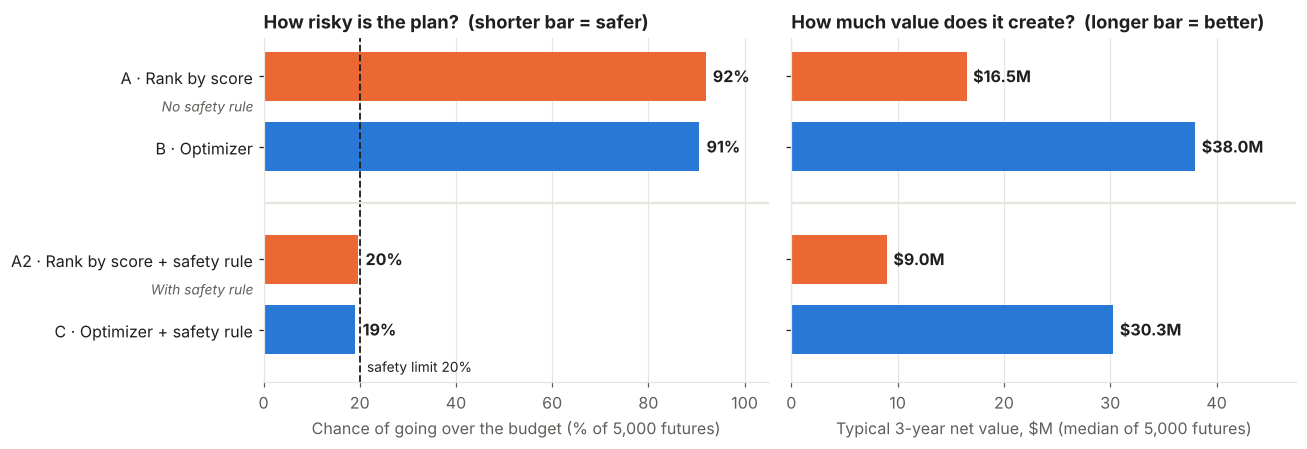

In [29]:
chart_risk_and_value(sims, save="images/risk_and_value.png")

**What it shows**
1. **Top two rows:** both plans without the safety rule go over budget about 9 times in 10 (≈90%). The optimizer (B) still creates more value than ranking (A): \$38.0M vs. \$16.5M, **≈2.3×**.
2. **Bottom two rows:** with the safety rule both plans sit at about 20% risk, which is equally safe. Now compare their value: **C \$30.3M vs. A2 \$9.0M, ≈3.4×**. Same safety, different method. **This is the main result.**

### 6.3 Chart: what does each plan *really* cost?
**How to read this chart**
- One small panel per plan, laid out like the 2 × 2 grid above: top row = no safety rule, bottom row = with the safety rule.
- Each panel is a **histogram**: we simulated the plan 5,000 times. Each bar counts how many futures ended with a total cost in that range. The taller the bar, the more often that cost happened.
- The **dashed line is the \$100M budget**. Bars to its **right are colored red**: those are futures that went **over budget**.
- The red text gives the share of futures over budget. "Typical cost" is the middle future.

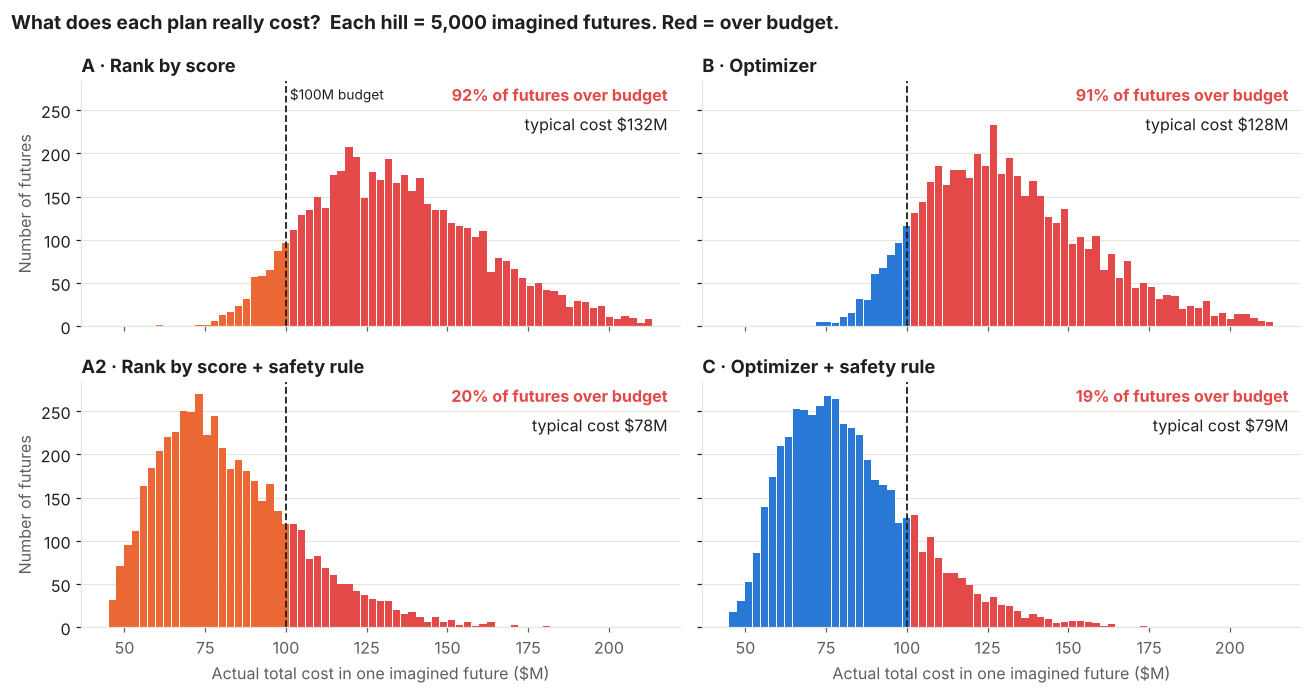

In [30]:
chart_cost_futures(sims, BUDGET, save="images/cost_futures.png")

**What it shows:** in the **top row** (no safety rule) almost the whole hill is red, sitting around \$130M: these plans almost always overrun. In the **bottom row** (safety rule) most of the hill sits left of \$100M, with only a small red tail (about 20%).

### 6.4 Why is C worth so much more than A2? Look inside both plans
The last column is each project's value **if everything went exactly to plan**: benefit per quarter × quarters of benefit before quarter 12 − cost.

In [31]:
for k in ["A2", "C"]:
    p = plans[k]["plan"][["start_q"]].join(df[["name", "strategic_score", "cost_musd", "benefit_musd_per_q", "duration_q"]])
    p["value_if_all_goes_to_plan"] = (p.benefit_musd_per_q * (12 - (p.start_q + p.duration_q)).clip(lower=0) - p.cost_musd).round(1)
    print(f"Plan {k}: {len(p)} projects | typical value after simulating overruns and delays: ${sims[k]['net_value_p50']}M")
    display(p)

Plan A2: 6 projects | typical value after simulating overruns and delays: $9.0M


,start_q,name,strategic_score,cost_musd,benefit_musd_per_q,duration_q,value_if_all_goes_to_plan
id,,,,,,,
P04,0,Battery supplier dual-sourcing,5,4.9,0.56,3,0.1
P11,0,Cybersecurity (UNECE R155),5,12.7,2.56,3,10.3
P03,0,EV platform cost-down,10,8.6,1.77,3,7.3
P15,0,Factory IoT data lake,10,4.9,0.83,2,3.4
P25,3,EU battery passport (regulatory),4,13.9,3.38,3,6.4
P30,3,Supplier risk early-warning,10,14.2,4.89,3,15.1


Plan C: 12 projects | typical value after simulating overruns and delays: $30.3M


,start_q,name,strategic_score,cost_musd,benefit_musd_per_q,duration_q,value_if_all_goes_to_plan
id,,,,,,,
P04,0,Battery supplier dual-sourcing,5,4.9,0.56,3,0.1
P06,0,OTA update platform,9,2.3,0.47,2,2.4
P09,0,Vehicle OS consolidation,9,3.1,0.85,2,5.4
P10,0,Digital twin of drivetrain,6,1.8,0.32,1,1.7
P14,0,Vision-based quality inspection,7,1.7,0.58,1,4.7
P30,0,Supplier risk early-warning,10,14.2,4.89,3,29.8
P28,0,Identity & access modernization,3,2.2,0.36,1,1.8
P11,1,Cybersecurity (UNECE R155),5,12.7,2.56,3,7.8
P27,1,Cloud cost optimization,5,1.3,0.20,1,0.7


**Three differences explain it:**
1. **Timing.** P30 (Supplier risk early-warning) is in both plans. A2 starts it in quarter 3 (value \$15.1M); C starts it in quarter 0 (value \$29.8M). **Same project, double the value, just by starting earlier.**
2. **Score ≠ value.** A2 funds "score 10" projects such as EV platform cost-down that earn little for their price.
3. **Small, cheap wins.** C adds quick, profitable projects (P09, P14, P06…) that ranking by score overlooked.

The totals in the last column are higher than the "typical value" because they assume no overruns or delays. The simulation adds reality.

---
## Step 7: What-if scenarios

Because the plan is produced by code, we can change one thing, rerun, and compare to the **Base** (normal) plan in seconds. Each scenario below reruns the full step-5 process (optimizer + safety rule) with one setting changed:
| Scenario | Setting changed |
|---|---|
| Base | nothing: \$100M, 20% risk |
| Budget cut 15% | budget = \$85M |
| CFO wants only 10% risk | safety rule = 10% instead of 20% |
| Must do the ERP project now | P23 (SAP finance migration) is forced in, as if leadership insisted |

In [32]:
scenarios = {
    "Base":                               dict(budget=BUDGET),
    "Budget cut 15%":                     dict(budget=BUDGET * 0.85),
    "CFO wants only 10% risk":            dict(budget=BUDGET, max_overrun_prob=0.10),
    "Must do the ERP project (P23) now":  dict(budget=BUDGET, force_in=("P23",)),
}
rows = []
for name, settings in scenarios.items():
    settings = dict(settings)
    b = settings.pop("budget")
    plan = optimize_risk_aware(df, deps, cap, b, **settings)["plan"]
    s = simulate_plan(df, deps, plan, b)
    rows.append({"scenario": name, "projects": s["n_projects"], "typical value $M": s["net_value_p50"],
                 "chance over budget": f"{s['prob_over_budget']:.0%}"})
scen_table = pd.DataFrame(rows).set_index("scenario")
scen_table["change_vs_base ($M)"] = (scen_table["typical value $M"] - scen_table.loc["Base", "typical value $M"]).round(1)
scen_table

,projects,typical value $M,chance over budget,change_vs_base ($M)
scenario,,,,
Base,12,30.3,19%,0.0
Budget cut 15%,12,20.2,19%,-10.1
CFO wants only 10% risk,14,19.4,9%,-10.9
Must do the ERP project (P23) now,16,17.2,19%,-13.1


**How to read the table:** `change_vs_base` is each row's typical value minus the Base row's (\$30.3M). For example: 17.2 − 30.3 = **−13.1**.

**How to read the chart below:** each bar is one decision. **Grey bars to the left of zero** lose value; blue bars to the right would gain value. The number is how much.

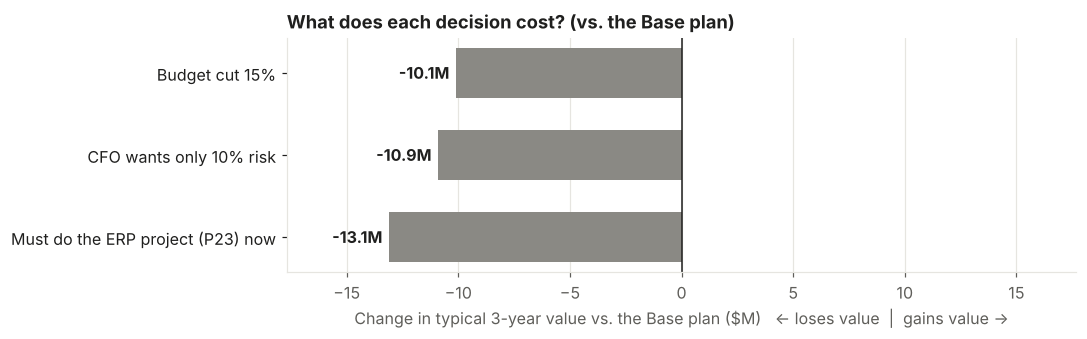

In [33]:
chart_change_vs_base(scen_table, "What does each decision cost? (vs. the Base plan)", save="images/scenarios.png")

**What it shows**
- **Budget cut 15%:** losing \$15M of budget costs about **\$10M** of value.
- **Only 10% risk:** the chance of overrunning falls to about 9%, but the extra safety **costs about \$11M**. Safety isn't free, and now it has a price tag.
- **Forcing ERP in** (expensive, slow to pay back) pushes out better projects and **costs about \$13M**.

The discussion changes from opinions to facts: *"Forcing the ERP project costs \$13M. Is that worth it to us?"*

### 7.1 Which team is the bottleneck?
A **bottleneck** is the narrow neck of a bottle: the one limit that actually holds you back. To find it, we change each team's size and rerun the optimizer. `capacity_factor` multiplies a team's size: **0.75 = lose a quarter of the people**, 1.25 = hire a quarter more.

This test uses **Plan B** (the full \$100M, no safety rule) as its Base, because Plan C is so careful with money that team size barely matters there. To see the team effect, we need the plan that uses the teams fully.

,projects,typical value $M,change_vs_base ($M)
scenario,,,
Base (Plan B),18,38.0,0.0
Lose 25% of software engineers,18,38.0,0.0
Lose 25% of the data/AI team,19,27.0,-11.0
Hire 25% more data/AI people,19,38.9,0.9


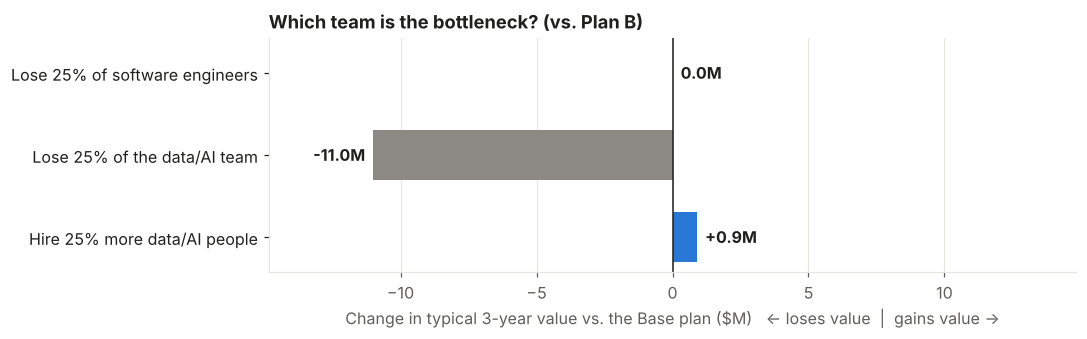

In [34]:
rows = []
for name, cf in {"Base (Plan B)": {}, "Lose 25% of software engineers": {"software": 0.75},
                 "Lose 25% of the data/AI team": {"data_ai": 0.75}, "Hire 25% more data/AI people": {"data_ai": 1.25}}.items():
    s = simulate_plan(df, deps, optimize(df, deps, cap, BUDGET, capacity_factor=cf)["plan"], BUDGET)
    rows.append({"scenario": name, "projects": s["n_projects"], "typical value $M": s["net_value_p50"]})
team_table = pd.DataFrame(rows).set_index("scenario")
team_table["change_vs_base ($M)"] = (team_table["typical value $M"] - team_table.loc["Base (Plan B)", "typical value $M"]).round(1)
display(team_table)
chart_change_vs_base(team_table, "Which team is the bottleneck? (vs. Plan B)", save="images/bottleneck.png")

**What it shows**
- **Lose 25% of software engineers: \$0 change.** There are spare software people, so they're not the limit.
- **Lose 25% of the data/AI team: −\$11M.** Some projects can no longer be staffed, so **the data/AI team is the bottleneck.**
- **Hire 25% more data/AI people: only +\$0.9M.** Once that team is big enough, **money** becomes the limit again.

👉 **Advice:** *retain the data/AI team (losing people is expensive); hiring more adds little.*

---
## Step 8: How much value does each budget level buy? (efficient frontier)

We rerun the step-5 process (optimizer + 20% safety rule) at budgets from \$60M to \$140M. The **efficient frontier** is the best value achievable at each budget.

In [35]:
fr = []
for b in [60, 70, 80, 90, 100, 110, 120, 140]:
    r = optimize_risk_aware(df, deps, cap, b, time_limit=5)
    if r["plan"].empty:
        continue
    s = simulate_plan(df, deps, r["plan"], b)
    fr.append((b, s["net_value_p10"], s["net_value_p50"], s["net_value_p90"]))
fr = pd.DataFrame(fr, columns=["budget", "p10", "p50", "p90"])
fr["extra value vs previous step"] = fr.p50.diff().round(1)
fr

,budget,p10,p50,p90,extra value vs previous step
0,60,-28.4,4.2,23.3,NaN
1,70,-22.0,11.8,31.6,7.6
2,80,-17.5,17.6,39.2,5.8
3,90,-14.0,20.4,43.3,2.8
4,100,-13.4,30.3,59.5,9.9
5,110,-13.9,30.4,61.4,0.1
6,120,-16.1,36.5,72.4,6.1
7,140,-21.0,33.6,72.2,-2.9


**How to read the charts below**
- **Left:** the dots are the **typical value** at each budget. The light shaded band runs from the **bad case (P10)** to the **good case (P90)**, showing the uncertainty. The dotted line marks today's \$100M.
- **Right:** how much **extra** typical value each budget step buys. Blue = a gain; grey = nothing or a loss.

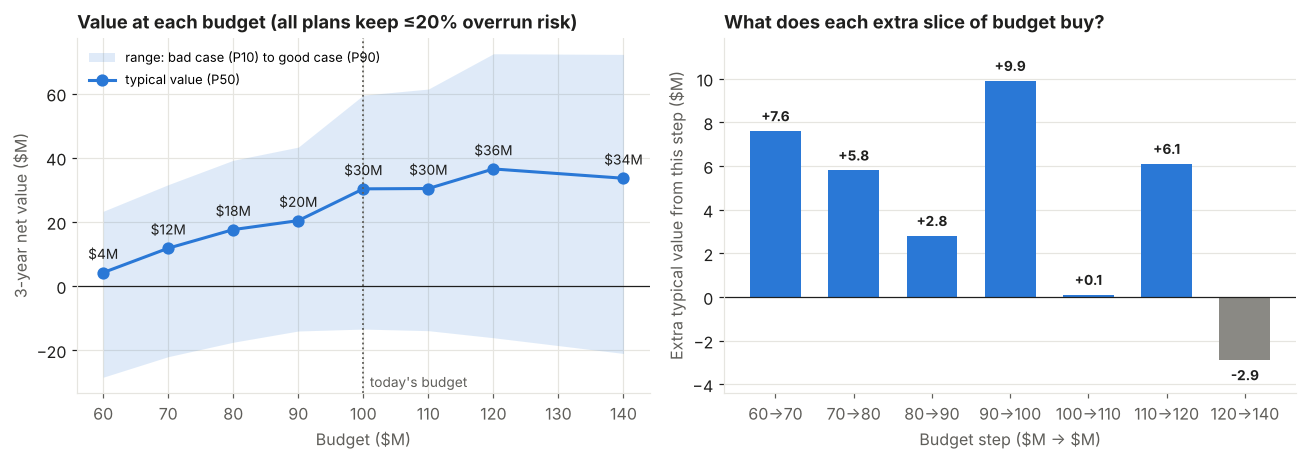

In [36]:
chart_frontier(fr, current_budget=BUDGET, save="images/frontier.png")

**What it shows**
- Up to about **\$100–120M**, more budget buys real value.
- After about **\$120M**, the line flattens and even dips: **diminishing returns**. The best projects are already funded, so extra money goes to weaker, riskier ones. The shaded band also widens downward: the bad case gets worse.
- The steps are bumpy because projects come in whole chunks (you can't fund half a project).

👉 **Answer to "should we raise the budget?":** going from \$100M to \$120M adds about \$6M of typical value. Beyond \$120M, it adds risk, not value.

---
## Step 9: The roadmap (Plan C)

**How to read this chart**
- Each **bar is one project**. It starts at the quarter the project starts and ends at the quarter it finishes. The bar's length = its duration.
- The x-axis shows **Y1 Q1 … Y2 Q4** (Year 1 Quarter 1 through Year 2 Quarter 4). The darker vertical line separates year 1 from year 2.
- **Color = strategic theme** (legend at the bottom).
- **★ required by law** marks the legal projects. **"after P04"** means it can only start once P04 is finished (a dependency).

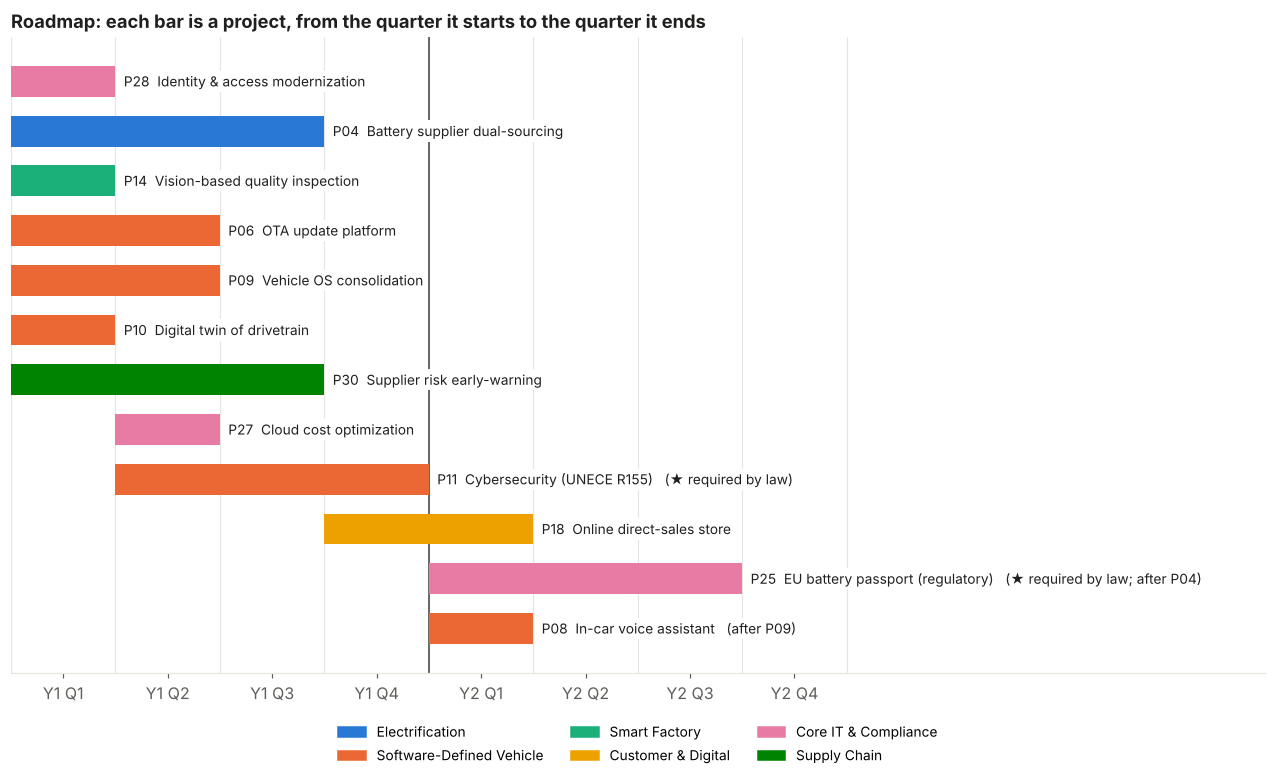

In [37]:
chart_roadmap(planC["plan"], df, deps, save="images/roadmap.png")

**What it shows:** most projects start in Y1 Q1, so value starts flowing early. The legal projects are scheduled so they finish in time. **P25 (EU battery passport) waits until P04 (battery dual-sourcing) is done**, exactly as the dependency requires.

**Why are there small gaps** (e.g. P04 ends in Y1 Q3 but P25 starts in Y2 Q1)? The bars show the teams' *planned* durations, but the safe plan was scheduled with *realistic* durations (P04 realistically takes 4 quarters, not 3). The gap is a deliberate **time buffer** for delays.

### 10.3 Why the notebook creates a file here
An MCP server must run as a **separate program** that an AI app starts in the background. A program can't run *inside* a notebook, so this notebook **writes the server file for you**. You never need to open or edit it.

**Part A:** save the engine functions we already wrote above into `portfolio_engine.py`, so the server can use them. `inspect.getsource()` copies each function's code exactly as it's written in this notebook.

In [38]:
header = (
    '"""Engine functions, auto-saved from Nordhavn_Portfolio_Optimization.ipynb (Step 10). Edit the notebook, not this file."""\n'
    "import numpy as np\nimport pandas as pd\nfrom ortools.sat.python import cp_model\n\n"
    f"SKILLS = {SKILLS!r}\nPLAN_Q = {PLAN_Q}\nBENEFIT_H = {BENEFIT_H}\nSIGMA = {SIGMA!r}\nTAIL_P = {TAIL_P!r}\n\n\n"
)
functions = [load, sample_multipliers, risk_profile, simulate_plan, greedy_by_score, optimize, optimize_risk_aware]
with open("portfolio_engine.py", "w") as f:
    f.write(header + "\n\n\n".join(inspect.getsource(fn) for fn in functions))
print("Saved portfolio_engine.py with:", [fn.__name__ for fn in functions])

Saved portfolio_engine.py with: ['load', 'sample_multipliers', 'risk_profile', 'simulate_plan', 'greedy_by_score', 'optimize', 'optimize_risk_aware']


**Part B:** write the MCP server itself. `%%writefile` at the top of a cell means **"save this cell's text as a file"** instead of running it.

It turns 5 functions into **tools**:
| Tool | What it does | Example question it answers |
|---|---|---|
| `list_initiatives` | lists the candidate projects | "What Smart Factory projects do we have?" |
| `project_risk` | risk profile of chosen projects | "How risky is P30?" |
| `simulate_portfolio` | stress-tests a plan the user proposes | "If we do P01, P30 and P11, what's our overrun risk?" |
| `optimize_portfolio` | builds the best safe plan | "Budget is \$85M. What should we fund?" |
| `compare_scenarios` | runs several what-ifs side by side | "Compare \$100M vs. \$85M vs. losing data people" |

A tool is just a **normal Python function** with `@mcp.tool()` above it. The AI reads three things: the **function name**, the **input types** (e.g. `budget_musd: float` = a number) and the **docstring** (the description in triple quotes). The docstring is the instruction manual the AI uses to decide when to call the tool.

In [39]:
%%writefile mcp_server.py
"""
mcp_server.py (auto-written by the notebook, Step 10): makes the engine usable by AI assistants through MCP (Model Context Protocol).

What is this?
  An AI assistant (an LLM such as Claude) is great at understanding questions, but it should not do
  optimization math in its head: it could make numbers up. MCP is an open standard that lets an AI app
  discover and call real tools. This file turns five Python functions into MCP "tools".
  A manager can then ask in plain English:
      "We just lost $15M of budget. What should we fund, and what's our risk of overrunning?"
  The AI calls optimize_portfolio(budget_musd=85), our solver computes the answer, and the AI explains it.

Run it:     python mcp_server.py        (it waits quietly for an AI app to connect over "stdio")
Test it:    Step 10.4 of the notebook (it acts like an AI app)
"""
import json
import pandas as pd
from mcp.server.fastmcp import FastMCP
from portfolio_engine import load, optimize_risk_aware, simulate_plan, risk_profile

mcp = FastMCP("portfolio-intelligence", log_level="ERROR")   # server name as AI apps see it; only log errors
DF, DEPS, CAP = load()                     # load the portfolio data once when the server starts


def _summary(sim):
    """Remove the big raw arrays (5,000 numbers) before sending results to the AI."""
    return {k: v for k, v in sim.items() if not k.startswith("_")}


# Each @mcp.tool() below becomes a tool. The AI reads the function NAME, the INPUT TYPES and the
# DOCSTRING (the text in triple quotes) to decide when and how to call it, so the docstrings are written for the AI.

@mcp.tool()
def list_initiatives(theme: str | None = None) -> str:
    """List candidate projects with cost ($M), duration (quarters), quarterly benefit ($M),
    strategic score (1-10), theme and whether it is legally required. Optionally filter by theme."""
    d = DF if theme is None else DF[DF.theme.str.contains(theme, case=False)]
    cols = ["name", "theme", "cost_musd", "duration_q", "benefit_musd_per_q", "strategic_score", "mandatory"]
    return d[cols].reset_index().to_json(orient="records")


@mcp.tool()
def project_risk(project_ids: list[str]) -> str:
    """Monte Carlo risk profile for specific projects (ids like "P30"): average overrun %,
    typical (P50) and cautious (P80) cost, and cautious (P80) duration."""
    rp = risk_profile(DF).loc[project_ids, ["name", "cost_musd", "cost_p50", "cost_p80",
                                            "duration_q", "dur_p80", "mean_cost_overrun_%"]]
    return rp.round(2).reset_index().to_json(orient="records")


@mcp.tool()
def simulate_portfolio(project_ids: list[str], start_quarters: list[int], budget_musd: float) -> str:
    """Stress-test a proposed plan (project ids + start quarter for each) in 5,000 simulated futures.
    Returns the chance of exceeding the budget, typical and cautious cost, the value range
    (bad case P10, typical P50, good case P90) and each project's chance of slipping more than a quarter."""
    plan = pd.DataFrame({"start_q": start_quarters}, index=pd.Index(project_ids, name="id"))
    return json.dumps(_summary(simulate_plan(DF, DEPS, plan, budget_musd)))


@mcp.tool()
def optimize_portfolio(budget_musd: float, max_overrun_prob: float = 0.2,
                       must_include: list[str] = [], must_exclude: list[str] = [],
                       capacity_change: dict[str, float] = {}) -> str:
    """Find the most valuable set of projects and their start quarters (OR-Tools CP-SAT solver),
    respecting budget, team capacity (teams: software, data_ai, mechanical, pmo), dependencies and
    legally required projects, with at most `max_overrun_prob` chance that actual cost exceeds the budget.
    capacity_change example: {"data_ai": 0.75} means the data/AI team is 25% smaller."""
    r = optimize_risk_aware(DF, DEPS, CAP, budget_musd, max_overrun_prob,
                            force_in=tuple(must_include), force_out=tuple(must_exclude),
                            capacity_factor=capacity_change)
    if r["plan"].empty:
        return json.dumps({"status": "INFEASIBLE",
                           "hint": "Increase the budget, accept more risk, or remove must-include projects."})
    sim = _summary(simulate_plan(DF, DEPS, r["plan"], budget_musd))
    return json.dumps({"status": r["status"], "contingency_reserve_musd": r["contingency_reserve"],
                       "plan": r["plan"].reset_index()[["id", "name", "start_q", "planned_cost"]].to_dict("records"),
                       "risk": sim})


@mcp.tool()
def compare_scenarios(scenarios: list[dict]) -> str:
    """Run several what-if scenarios side by side. Each scenario is a dict with keys: name, budget_musd and
    optionally max_overrun_prob, must_include, must_exclude, capacity_change.
    Returns, per scenario: number of projects, typical value, bad-case value and chance of going over budget."""
    out = []
    for s in scenarios:
        r = json.loads(optimize_portfolio(s["budget_musd"], s.get("max_overrun_prob", 0.2), s.get("must_include", []),
                                          s.get("must_exclude", []), s.get("capacity_change", {})))
        if r["status"] == "INFEASIBLE":
            out.append({"name": s.get("name"), "status": "INFEASIBLE"})
            continue
        out.append({"name": s.get("name"), "n_projects": len(r["plan"]), "net_value_p50": r["risk"]["net_value_p50"],
                    "net_value_p10": r["risk"]["net_value_p10"], "prob_over_budget": r["risk"]["prob_over_budget"]})
    return json.dumps(out)


if __name__ == "__main__":
    mcp.run()   # start the server and wait for an AI app to connect


Writing mcp_server.py


### 10.4 Test it: this notebook pretends to be an AI app
The next cell does exactly what an AI app does behind the scenes:
1. **starts** the server program (`mcp_server.py`)
2. asks **"which tools do you have?"**
3. **calls** `compare_scenarios` with three what-ifs: \$100M, \$85M, and losing a quarter of the data/AI team

`async with` / `await` is Python's way of talking to another program and waiting for its answer. It takes about 30–60 seconds, because the optimizer runs several times.

In [40]:
from mcp import ClientSession, StdioServerParameters
from mcp.client.stdio import stdio_client

server = StdioServerParameters(command=sys.executable, args=["mcp_server.py"])
async with stdio_client(server, errlog=open(os.devnull, "w")) as (read, write):   # 1. start the server and connect
    async with ClientSession(read, write) as session:
        await session.initialize()                                                # hello / handshake
        tools = await session.list_tools()                                        # 2. which tools do you have?
        print("Tools the AI can see:", [t.name for t in tools.tools])
        result = await session.call_tool("compare_scenarios", {"scenarios": [    # 3. call one tool
            {"name": "Base $100M", "budget_musd": 100},
            {"name": "Budget cut to $85M", "budget_musd": 85},
            {"name": "Lose a quarter of the data/AI team", "budget_musd": 100, "capacity_change": {"data_ai": 0.75}},
        ]})
answer = json.loads(result.content[0].text)
pd.DataFrame(answer).set_index("name")

Tools the AI can see: ['list_initiatives', 'project_risk', 'simulate_portfolio', 'optimize_portfolio', 'compare_scenarios']


,n_projects,net_value_p50,net_value_p10,prob_over_budget
name,,,,
Base $100M,12,30.3,-13.4,0.191
Budget cut to $85M,12,20.2,-14.2,0.193
Lose a quarter of the data/AI team,11,28.3,-16.5,0.196


**How to read the output**
- **"Tools the AI can see"** lists all 5 tools. The server announced them automatically; nobody had to program the AI app for this project. That's the point of MCP.
- The table has one row per scenario: `n_projects` (projects funded), `net_value_p50` (typical value, \$M), `net_value_p10` (bad-case value, \$M), `prob_over_budget` (0.191 = 19.1%).
- **Check:** Base = 30.3 and \$85M = 20.2, the **same numbers as Step 7**. The AI used the same engine, so its answers are real, not guessed.

A real AI assistant would turn this into a sentence like: *"With \$85M, typical value falls from about \$30M to \$20M, and the chance of overrunning stays around 19%."*

### 10.5 Try it with a real AI app (optional)
In a desktop AI app that supports MCP, add this to its MCP configuration (use the full path to `mcp_server.py` in this folder):
```json
{"mcpServers": {"portfolio": {"command": "python", "args": ["/full/path/to/mcp_server.py"]}}}
```
Restart the app, then ask: *"If our budget drops to $85M, what should we fund and how risky is it?"*

---
## Conclusions

1. **Plans built on point estimates almost always overrun.** With typical overruns of about 27%, filling the budget to 100% gave about a **92%** chance of going over.
2. **Optimizing combinations and timing beats ranking by score.** At the same budget: **≈2.3×** the typical value. At the same 20% risk: **≈3.4×**.
3. **Manage risk at the portfolio level.** Padding every project to its P80 was impossible and wasteful. A portfolio-level chance constraint kept about **\$15M** as a contingency reserve.
4. **Every decision has a price tag.** A 15% budget cut ≈ −\$10M; demanding 10% risk ≈ −\$11M; forcing the ERP project ≈ −\$13M.
5. **The data/AI team is the bottleneck.** Losing a quarter of it ≈ −\$11M; software engineers aren't a constraint.
6. **Diminishing returns above ≈\$120M.** Extra budget beyond that buys risk, not value.
7. **AI-ready.** The engine is exposed through MCP, so an AI assistant can answer what-if questions with numbers from the solver rather than guesses.

## Limitations and next steps
- **Synthetic data.** Next: calibrate the risk model on real planned-vs-actual project history (for example the public project database of Batselier & Vanhoucke, or a company's own records).
- **Resource contention.** The Monte Carlo model propagates delays through dependencies, but it doesn't model projects *queuing* for the same team. Next: a discrete-event simulation (e.g. with SimPy).
- **Benefits are treated as known.** Next: a machine-learning model that predicts delivery delays and benefits from project features, feeding its uncertainty into the simulation.
- **Dependencies are a hand-made table.** In a real system they'd come from a knowledge graph of goals → initiatives → tasks → people.
- **Search method.** The bisection keeps the plan from the largest passing planning budget. Keeping the *most valuable* passing plan, or using sample-average approximation / stochastic programming, would be more rigorous.

## References
- Flyvbjerg, B. & Budzier, A. (2011). *Why Your IT Project May Be Riskier Than You Think.* Harvard Business Review.
- Google OR-Tools CP-SAT solver: developers.google.com/optimization
- Model Context Protocol: modelcontextprotocol.io